In [3]:
# -- uncomment to get interactive plots
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pmoired

# -- in case you want to limit the number of cores for the multiprocessing functions
# -- will take all CPUs otherwise! 
pmoired.MAX_THREADS = 6 
print('will use', pmoired.MAX_THREADS, 'CPUs for multiprocessing')

will use 6 CPUs for multiprocessing


loadOI: loading MIRC_L2.2014Aug02.GL_586A.MIRCX_IDL.MCJ.SPLIT.oifits
  > insname: "H_PRISM" targname: "GL_586A" pipeline: "" calibrated: unknown
  > MJD: (315,) [56871.1774..56871.2192] ~2014-08-02T04:41:35.540
  > E2-S2-W1-W2 | WL: (6,) [ 1.514 .. 1.692 ] um (R~46 P~45) {'T3': 4, 'VIS': 6, 'VIS2': 6} | TELL: False 


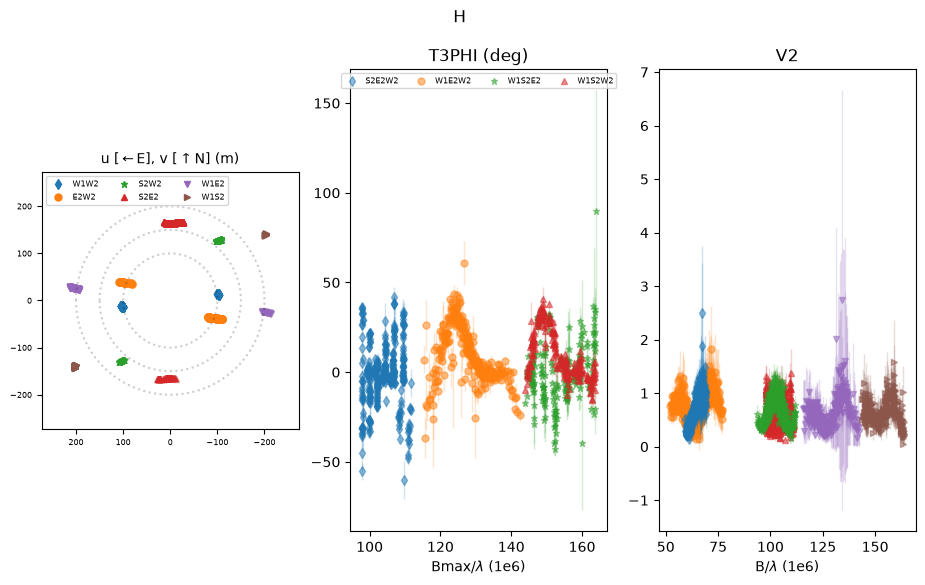

In [5]:
oi = pmoired.OI('MIRC_L2.2014Aug02.GL_586A.MIRCX_IDL.MCJ.SPLIT.oifits') #binning=3)
oi.show(obs=['V2', 'T3PHI'])

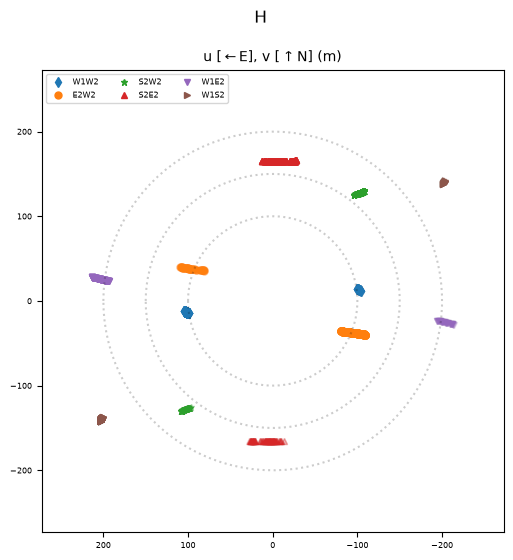

In [6]:
oi.show(obs=['']) # Show u, v only
# oi.show(obs=['V2']) 

In [4]:
plx = 51.1421 # mas from Gaia
R1 = 0.92 # From Strassmeier et al. 2013
R2 = 0.59 # From Strassmeier et al. 2013
R_Solar = 6.957e+8 # solar radii in meters
d_pc = 3.086e16 # pc in meters

data = oi.data[0]
print(data.keys())
print('\n')
print(f'Instrument: {data['insname']}')
print(f'Telescopes: {data['telescopes']}')
print(f'Baselines: {data['baselines']}')
print(f'Triangles: {data['triangles']}')
print('Mean MJD:', np.mean(data['MJD']))
print('Duration of Observation (min)', 24*60*(np.max(data['MJD']) - np.min(data['MJD'])))

dict_keys(['insname', 'filename', 'targname', 'pipeline', 'LST', 'header', 'calibrated', 'WL', 'dWL', 'OI_VIS2', 'OI_VIS', 'OI_T3', 'units', 'telescopes', 'baselines', 'triangles', 'TELLURICS', 'configurations per MJD', 'MJD', 'recipes'])


Instrument: H_PRISM
Telescopes: ['E2', 'S2', 'W2']
Baselines: ['E2W2', 'S2E2', 'S2W2']
Triangles: ['S2E2W2']
Mean MJD: 56867.183318367184
Duration of Observation (min) 17.50555007136427


In [5]:
wl = data['WL']
d_wl = data['dWL']
print(f'Lambda (um)', wl)
print('Delta Lambda (um)', d_wl)
print('Spectral Resolution R', wl/d_wl)


wl_min = np.min(wl)
wl_max = np.max(wl)
wl_mean = np.mean(wl)
R_mean = np.mean(wl/d_wl)
print('Mean Wavelength (um):',wl_mean)
print('Mean R:', R_mean)


Lambda (um) [1.48529011 1.51428094 1.55092243 1.58704938 1.62266167 1.65775941
 1.69234249 1.72585044]
Delta Lambda (um) [0.0251656  0.03281616 0.03638422 0.03586962 0.03535501 0.03484041
 0.03404551 0.03297043]
Spectral Resolution R [59.02064068 46.14436661 42.62623618 44.24494751 45.89622362 47.58151077
 49.70823879 52.34539724]
Mean Wavelength (um): 1.6045196105096693
Mean R: 48.44594517537905


In [6]:
# Get min and max baseline lengths for each baseline

data = oi.data[0]

baseline_lengths = {}                
for b in data['baselines']:
    v = data['OI_VIS2'][b]
    baseline_lengths[b] = np.hypot(v['u'], v['v'])   
    #print(b, np.round(baseline_lengths[b], 2))


max_baselines = []
min_baselines = []
print("Baseline, Min (m), Max (m)")
for b in data['baselines']:
    print(b, baseline_lengths[b].min(), baseline_lengths[b].max())
    max_baselines.append(baseline_lengths[b].max())
    min_baselines.append(baseline_lengths[b].min())
    # usually go to 1/4 * lamda/longest baseline


# MAXIMUM BASELINE LENGTHS (in meters) FOR EACH BASELINE:
# BASELINE: W1S2; 247.98848075397257 m
# WAVELENGTH: 1.587e-06 m

Bmax = np.max(max_baselines) # meters
Bmin = np.min(min_baselines) # meters
wavelength = wl_mean / 1e6 # meters
fineness_factor = 1/4
max_resolution = fineness_factor * (wavelength / Bmax) * 206265e3 # in mas, 0.329997742239 mas
print('Max Baseline', Bmax, 'm')
print('Min Baseline', Bmin, 'm')
print('Fringe Spacing', (wavelength / Bmax) * 206265e3, 'mas')
print(f'Maximum Resolution for Search', max_resolution, "mas")

Baseline, Min (m), Max (m)
E2W2 115.92747584593675 122.56303931444002
S2E2 165.92469620981237 167.35943575798754
S2W2 155.0804795051514 158.26078091918703
Max Baseline 167.35943575798754 m
Min Baseline 115.92747584593675 m
Fringe Spacing 1.9775176461538797 mas
Maximum Resolution for Search 0.4943794115384699 mas


In [7]:
# Angular Diameter Calculation

theta_ud1 = 206265e3 * ((2 * R1 * R_Solar) / ((1/(plx*1e-3)) * d_pc))
theta_ud2 = 206265e3 * ((2 * R2 * R_Solar) / ((1/(plx*1e-3)) * d_pc))
print('UD1:',theta_ud1)
print('UD2:',theta_ud2)

UD1: 0.43757046743171013
UD2: 0.2806158432442489


setupFit> 0/H_PRISM: setting 'wl kernel':1.0 according to WL definition
1536 grid points not within constraints
Sun Nov  1 21:52:26 2026: running 5025 fits on 10 processes
Sun Nov  1 21:54:09 2026: [████████████████████████████████████████████████████████████]5025/5025   0s   left

Sun Nov  1 21:54:09 2026: it took 102.5s, 0.02s per fit on average [2940.7 fit/minute]
fits to be taken into account: 4903 / 5025
  122 have uncertainties larger than the grid's step[s]
Sun Nov  1 21:54:09 2026: making list of unique minima...
Sun Nov  1 21:55:30 2026: [████████████████████████████████████████████████████████████]4903/4903   0s   left

unique minima: 4872 / 4903 [~1.0 first guesses / minima]
  WARNING!: too many unique minima -> grid too coarse / Nfits too small?  finding the global minimum may be unreliable
Sun Nov  1 21:55:30 2026: linking unique minima to first guess(es)
Sun Nov  1 21:55:30 2026: done
------------
best fit: chi2= 3.124191117328477
{'B,x': -4.609, # +/- 0.058
'B,y': 0.588,

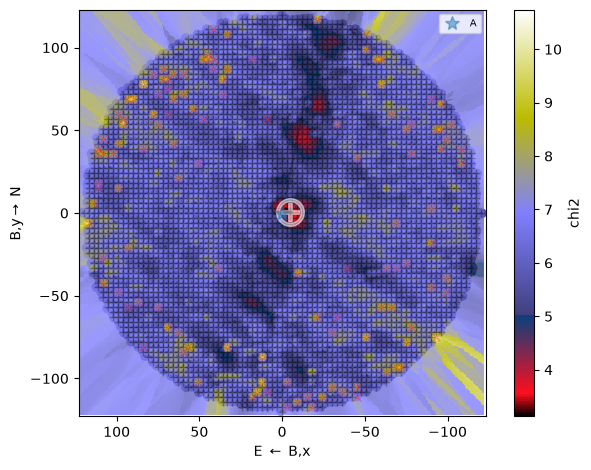

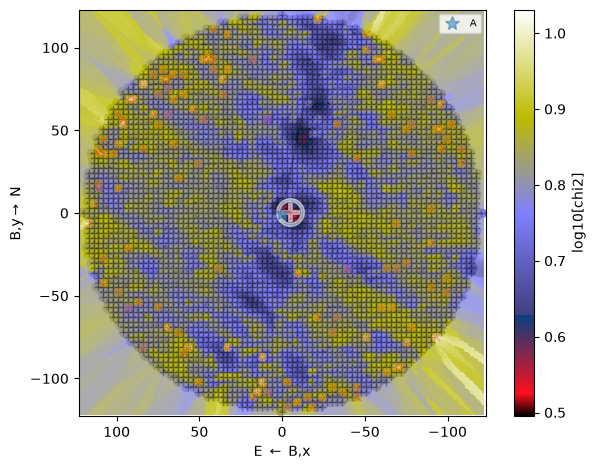

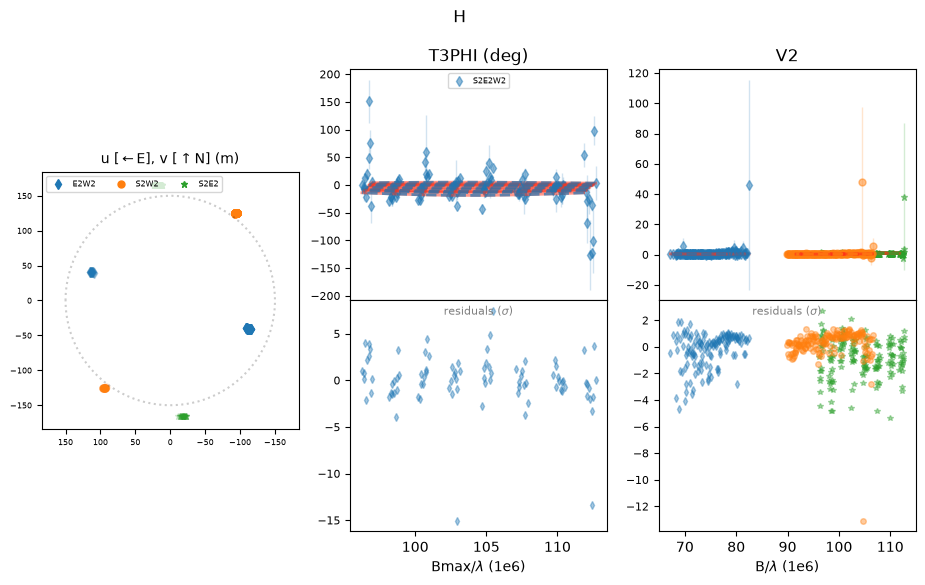

In [ ]:
# Define model
# A at the origin, B offset (x East, y North, in mas)

maxsep1 = 120.0
step1 = 3  

param = {
    'A,f': 1.0,
    'A,ud': theta_ud1,      
    'A,x': 0.0, 'A,y': 0.0,
    'B,f': 0.2362529748,         # flux relative to A, initial guess at 2014-08-02 fit
    'B,ud': theta_ud2,      
    'B,x': 0.0, 'B,y': 0.0,
}

# Flux of B must be lower than A component
prior = [('B,f', '<', 1)]

# Constraints on B's position
# - Separation must be less than the maximum separation
constrain = [( 'np.sqrt(B,x**2+B,y**2)', '<', maxsep1)]


# parameters that will be fixed and not fitted
fixed = ['A,f', 'A,ud', 'A,x', 'A,y', 'B,ud'] # Fix B,f for bad fits


oi.setupFit({'obs': ['V2', 'T3PHI'], 'min relative error': {'V2': 0.01}})


# Grid search over B's position
expl = {'grid': {'B,x': (-maxsep1, maxsep1, step1), 'B,y': (-maxsep1, maxsep1, step1)}}
oi.gridFit(expl, model=param, doNotFit=fixed, constrain=constrain, prior=prior)

# -- show the grid result
oi.showGrid()

# -- show the log grid result
oi.showGrid(interpolate=True, logV=1)

# -- show the data and the best fit model
oi.show()

In [9]:
# list the distinct minima it found in the unzoomed, best first
rows1 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows1.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows1.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows1[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

-----------------------------------------
  chi2r    sep(mas)   PA(deg)   f_B/f_A
3.124191117328477  4.645989699657041  277.26919036921464  0.2362529748
3.257896803281608  1.5585393239291416  278.89275480329286  0.2362529748
3.2736621640800534  3.220051128790848  316.3847544475607  0.2362529748
3.3820924491460573  5.958442027773652  296.7387668146911  0.2362529748
3.4995069075031844  7.205188252347418  242.94313975326273  0.2362529748
3.534378879595859  2.1630640959641774  23.42655505610017  0.2362529748
3.572349141043324  9.915341076406328  252.72575991807548  0.2362529748
3.6789482304365397  10.163941877424618  265.3394456190013  0.2362529748


In [10]:
# The best fit position of component B, not zoomed in
x1 = oi.bestfit['best']['B,x']
y1 = oi.bestfit['best']['B,y']
pa1 = np.degrees(np.arctan2(x1, y1)) % 360
print(f'{x1}, {y1} mas, PA = {pa1} deg')

-4.608648140844696, 0.5878627418097264 mas, PA = 277.26919036921464 deg


Sun Nov  1 21:55:39 2026: running 1681 fits on 10 processes
Sun Nov  1 21:56:03 2026: [████████████████████████████████████████████████████████████]1681/1681   0s   left

Sun Nov  1 21:56:03 2026: it took 23.6s, 0.01s per fit on average [4267.8 fit/minute]
fits to be taken into account: 1679 / 1681
  2 have uncertainties larger than the grid's step[s]
Sun Nov  1 21:56:03 2026: making list of unique minima...
Sun Nov  1 21:56:04 2026: [████████████████████████████████████████████████████████████]1679/1679   0s   left

unique minima: 116 / 1679 [~14.5 first guesses / minima]
  few unique minima -> grid too fine / Nfits too large?
Sun Nov  1 21:56:04 2026: linking unique minima to first guess(es)
Sun Nov  1 21:56:04 2026: done
------------
best fit: chi2= 3.12419112337793
{'B,x': -4.609, # +/- 0.058
'B,y': 0.588, # +/- 0.013
'A,f': 1.0,
'A,ud':0.43757046743171013,
'A,x': 0.0,
'A,y': 0.0,
'B,f': 0.2362529748,
'B,ud':0.2806158432442489,
}

Correlations (%)  >=95 >=90 >=80 >=60 <60%
        

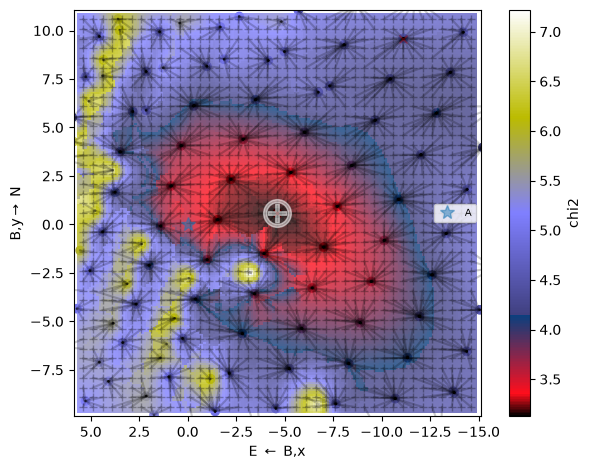

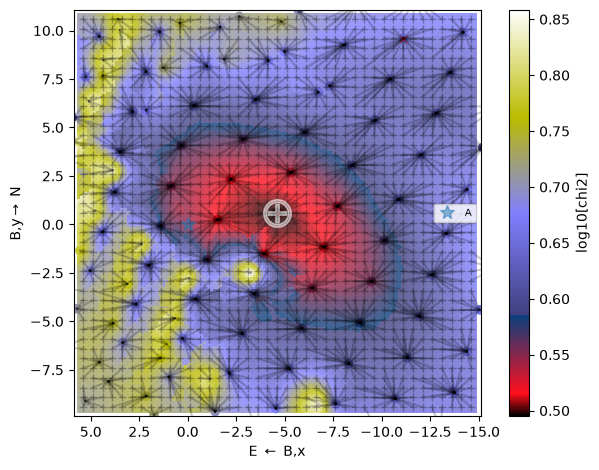

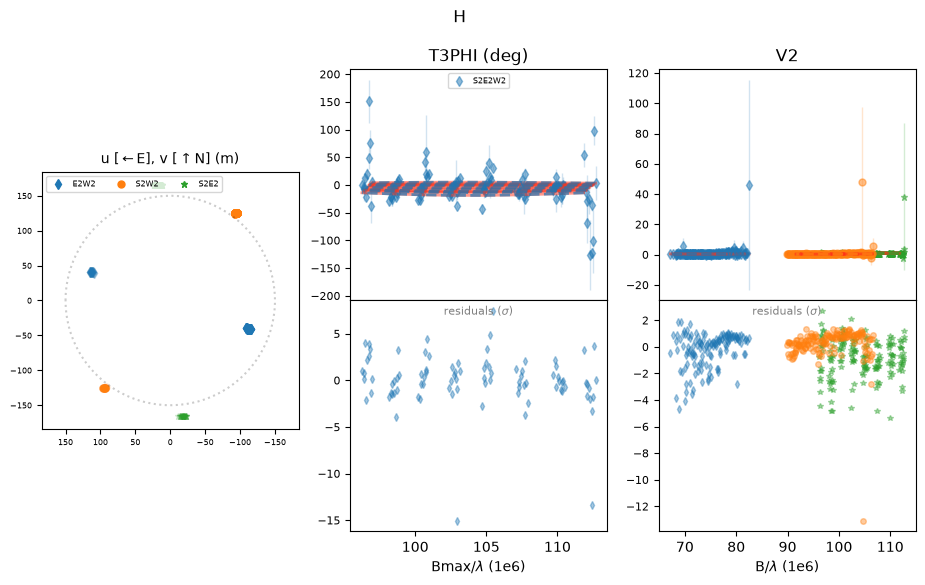

In [11]:
# Refine the fit around the best fit point (x1, y1)

maxsep2 = 10
step2 = max_resolution        # half-width and step, in mas

expl = {'grid': {'B,x': (x1-maxsep2, x1+maxsep2, step2),
                 'B,y': (y1-maxsep2, y1+maxsep2, step2)}}

oi.gridFit(expl, model=oi.bestfit['best'], doNotFit=fixed, prior=prior)   # no constrain
oi.showGrid()
oi.showGrid(interpolate=True, logV=1)
oi.show()

In [12]:
# list the distinct minima it found in the zoomed, best first
rows2 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows2.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows2.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows2[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

-----------------------------------------
  chi2r    sep(mas)   PA(deg)   f_B/f_A
3.12419112337793  4.646021558039346  277.26918903554395  0.2362529748
3.251904397127367  7.107593815225044  260.5324609934778  0.2362529748
3.257890080840716  1.5571323132546302  278.9033062644612  0.2362529748
3.2736594447039775  3.2200504904859755  316.3800346628941  0.2362529748
3.284518446528669  4.214941980119206  249.00302146995355  0.2362529748
3.3820827365279125  5.956709812649962  296.74202271791256  0.2362529748
3.4060955738013905  7.770556959313771  276.9201143763964  0.2362529748
3.4995021119031318  7.206081732294012  242.94785634268584  0.2362529748


In [13]:
# The best fit position of component B, zoomed in
x2 = oi.bestfit['best']['B,x']
y2 = oi.bestfit['best']['B,y']
pa2 = np.degrees(np.arctan2(x2, y2)) % 360
print(f'{x2}, {y2} mas, PA = {pa2} deg')

-4.608679756852994, 0.5878666656137056 mas, PA = 277.26918903554395 deg


Sun Nov  1 21:56:11 2026: running 10201 fits on 10 processes
Sun Nov  1 21:57:32 2026: [████████████████████████████████████████████████████████████]10201/10201   0s   left

Sun Nov  1 21:57:32 2026: it took 81.0s, 0.01s per fit on average [7556.5 fit/minute]
fits to be taken into account: 10196 / 10201
  5 have uncertainties larger than the grid's step[s]
Sun Nov  1 21:57:32 2026: making list of unique minima...
Sun Nov  1 21:57:33 2026: [████████████████████████████████████████████████████████████]10196/10196   0s   left

unique minima: 6 / 10196 [~1699.3 first guesses / minima]
  few unique minima -> grid too fine / Nfits too large?
Sun Nov  1 21:57:33 2026: linking unique minima to first guess(es)
Sun Nov  1 21:57:33 2026: done
------------
best fit: chi2= 3.1241911156737676
{'B,x': -4.609, # +/- 0.058
'B,y': 0.588, # +/- 0.013
'A,f': 1.0,
'A,ud':0.43757046743171013,
'A,x': 0.0,
'A,y': 0.0,
'B,f': 0.2362529748,
'B,ud':0.2806158432442489,
}

Correlations (%)  >=95 >=90 >=80 >=60 <60

/Users/ethanchen/ASTRO2/ASTRO399/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/Users/ethanchen/ASTRO2/ASTRO399/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


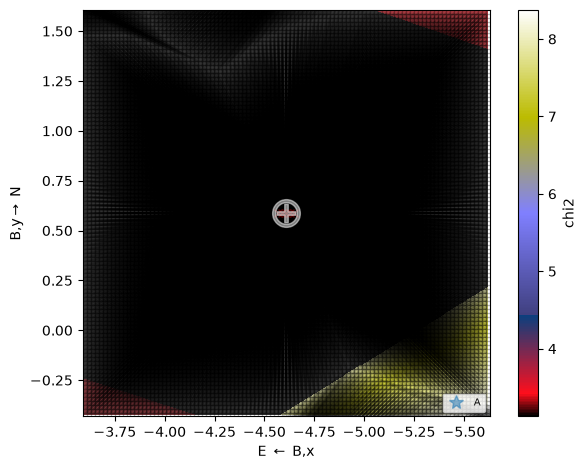

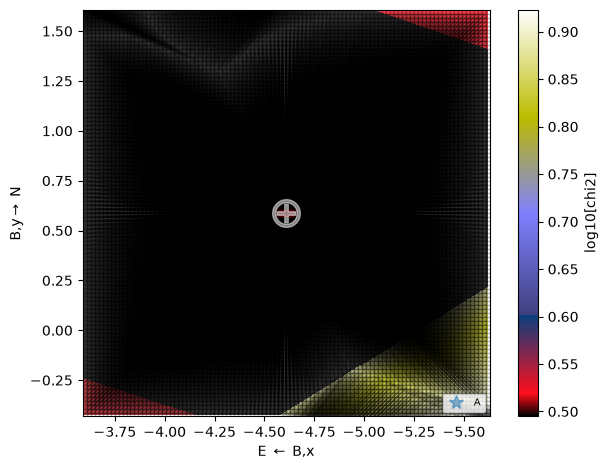

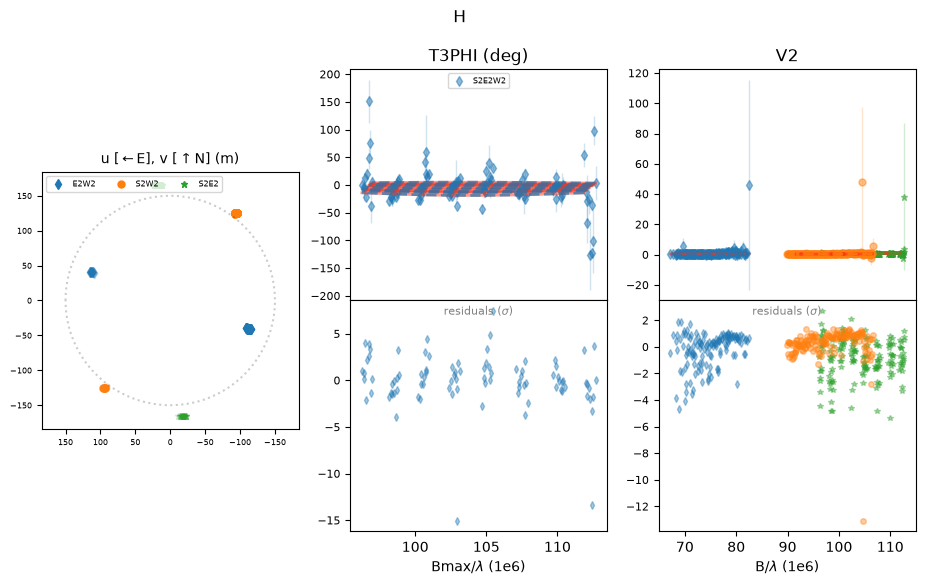

In [14]:
# Refine the fit around the best fit point

x3 = x2
y3 = y2
maxsep3 = 1
step3 = 0.02        # half-width and step, in mas

expl = {'grid': {'B,x': (x2-maxsep3, x2+maxsep3, step3),
                 'B,y': (y2-maxsep3, y2+maxsep3, step3)}}

oi.gridFit(expl, model=oi.bestfit['best'], doNotFit=fixed, prior=prior)   # no constrain
oi.showGrid()
oi.showGrid(interpolate=True, logV=1)
oi.show()

In [15]:
# list the distinct minima it found in the zoomed, best first
rows3 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows3.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows3.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows3[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

-----------------------------------------
  chi2r    sep(mas)   PA(deg)   f_B/f_A
3.1241911156737676  4.645984048413194  277.2691074244683  0.2362529748
3.251904363215967  7.10756510048435  260.5324499042416  0.2362529748
3.273659294292683  3.2200420140536745  316.3792103813248  0.2362529748
3.2845184297125383  4.214985045847297  249.00338861037696  0.2362529748
3.3820820089234713  5.957008807409355  296.740563031402  0.2362529748
8.380127473208866  5.5618739907085395  261.1596748097518  0.2362529748


In [16]:
# The best fit position of component B, zoomed in for a second time
x3 = oi.bestfit['best']['B,x']
y3 = oi.bestfit['best']['B,y']
pa3 = np.degrees(np.arctan2(x3, y3)) % 360
print(f'{x3}, {y3} mas, PA = {pa3} deg')

-4.60864338604089, 0.5878553550078571 mas, PA = 277.2691074244683 deg


[dpfit] 2 FITTED parameters: ['B,x', 'B,y']
[dpfit] epsfcn= 1e-06 ftol= 1e-05
[dpfit] using scipy.optimize.leastsq
[dpfit] Sun Nov  1 21:58:13 2026 001/000 CHI2: 3.1299e+00|
[dpfit] Both actual and predicted relative reductions in the sum of squares  are at most 0.000010
[dpfit] 4 function calls ( 2.558 ms on average)
# -- degrees of freedom: 548
# -- reduced chi2: 3.1298921943520046
{'B,x': -4.609, # +/- 0.058
'B,y': 0.588, # +/- 0.013
'A,f': 1.0,
'A,ud':0.43757046743171013,
'A,x': 0.0,
'A,y': 0.0,
'B,f': 0.2362529748,
'B,ud':0.2806158432442489,
}

Correlations (%)  >=95 >=90 >=80 >=60 <60%
        0   1  
 0:B,x ### -47 
 1:B,y -47 ### 


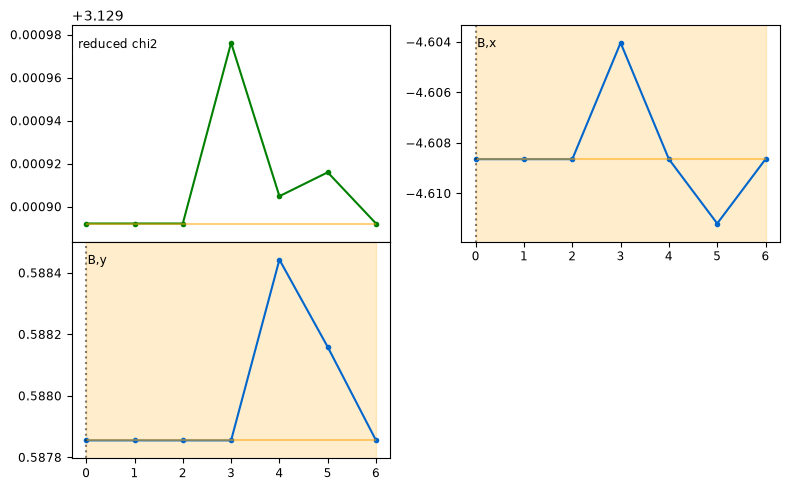

In [17]:
# Refine Fit using the zoomed best fit, Bx_zoom, By_zoom
oi.doFit(oi.bestfit['best'], doNotFit=fixed)
oi.showFit()

In [18]:
# Separation and position angle
b = oi.bestfit['best']
x, y = b['B,x'], b['B,y']
sep = np.hypot(x, y)
pa = np.degrees(np.arctan2(x, y)) % 360
print(f"sep = {sep} mas, PA = {pa} deg, f_B/f_A = {b['B,f']}")
print(x, y)

sep = 4.645984048413194 mas, PA = 277.2691074244683 deg, f_B/f_A = 0.2362529748
-4.60864338604089 0.5878553550078571


Sun Nov  1 21:58:13 2026: running 500 fits on 6 processes
Sun Nov  1 21:58:24 2026: [████████████████████████████████████████████████████████████]500/500   0s   left
Sun Nov  1 21:58:24 2026: it took 10.8s, 0.02s per fit on average [2788.6 fit/minutes]
{'B,x': -4.613, # +0.072 -0.151
'B,y': 0.589, # +0.040 -0.025
'A,f': 1.0,
'A,ud':0.43757046743171013,
'A,x': 0.0,
'A,y': 0.0,
'B,f': 0.2362529748,
'B,ud':0.2806158432442489,
}

Correlations (%)  >=95 >=90 >=80 >=60 <60%
        0   1  
 0:B,x ### -61  43 
 1:B,y -61 ###   8 
ellipse (emin, emax, PA) for B,x/B,y: 0.0323 0.1033 -73.8


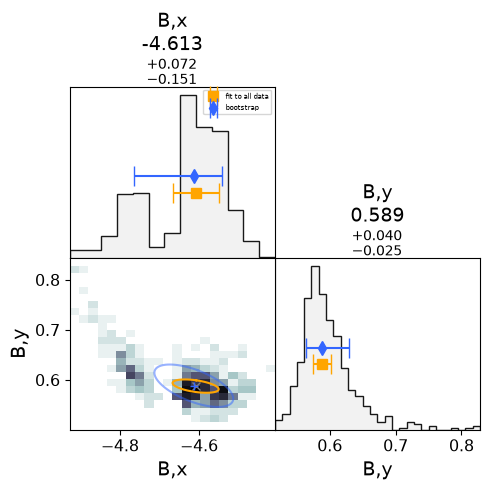

In [19]:
# Uncertainties

oi.bootstrapFit(Nfits=500)
oi.showBootstrap()

In [20]:
# BEST FIT PARAMETERS AND UNCERTAINTIES

# Separation and position angle
b = oi.bestfit['best']
x, y = b['B,x'], b['B,y']
sep = np.hypot(x, y)
pa = np.degrees(np.arctan2(x, y)) % 360
print(f"sep = {sep} mas, PA = {pa} deg, f_B/f_A = {b['B,f']}")
print(x, y)

sep = 4.645984048413194 mas, PA = 277.2691074244683 deg, f_B/f_A = 0.2362529748
-4.60864338604089 0.5878553550078571


In [21]:
# Summary of all the Grid Fits

print(f"Grid Size: {2*maxsep1} x {2*maxsep1} mas; Step = {step1} mas")
print(f"    Bx: {x1} mas; By: {y1} mas; PA = {pa1} deg")
print(f"Grid Size: {2*maxsep2} x {2*maxsep2} mas; Step = {step2} mas")
print(f"    Bx: {x2} mas; By: {y2} mas; PA = {pa2} deg")
print(f"Grid Size: {2*maxsep3} x {2*maxsep3} mas; Step = {step3} mas")
print(f"    Bx: {x3} mas; By: {y3} mas; PA = {pa3} deg")

Grid Size: 240.0 x 240.0 mas; Step = 3 mas
    Bx: -4.608648140844696 mas; By: 0.5878627418097264 mas; PA = 277.26919036921464 deg
Grid Size: 20 x 20 mas; Step = 0.4943794115384699 mas
    Bx: -4.608679756852994 mas; By: 0.5878666656137056 mas; PA = 277.26918903554395 deg
Grid Size: 2 x 2 mas; Step = 0.02 mas
    Bx: -4.60864338604089 mas; By: 0.5878553550078571 mas; PA = 277.2691074244683 deg


In [22]:
# More readable grids without the movement of the fits plotted
# The dofit model (not using grid fit and keeping Bx, By fixed) searches in an area centered around the best fit of the last gridfit model (x3, y3)


start = dict(oi.bestfit['best']) # includes x3, y3, B,f and the fixed params
start['B,x'] = x3
start['B,y'] = y3

x1_2, y1_2 = x3, y3

maxsep1_2 = 10
step1_2 = max_resolution       # half-width and step, in mas

xs = np.arange(x1_2-maxsep1_2, x1_2+maxsep1_2+step1_2/2, step1_2)
ys = np.arange(y1_2-maxsep1_2, y1_2+maxsep1_2+step1_2/2, step1_2)
frozen = fixed + ['B,x', 'B,y'] # B,f is still fitted at each point

chi2 = np.zeros((len(ys), len(xs)))

progress = 0

for j, y in enumerate(ys):
    for i, x in enumerate(xs):
        p = dict(start); p['B,x'], p['B,y'] = x, y
        oi.doFit(p, doNotFit=frozen, prior=prior, verbose=0)
        chi2[j, i] = oi.bestfit['chi2']

    progress += len(xs)
    print(f'{progress}/{len(xs)*len(ys)}')

oi.doFit(start, doNotFit=fixed, verbose=0)   # restore oi.bestfit

41/1681
82/1681
123/1681
164/1681
205/1681
246/1681
287/1681
328/1681
369/1681
410/1681
451/1681
492/1681
533/1681
574/1681
615/1681
656/1681
697/1681
738/1681
779/1681
820/1681
861/1681
902/1681
943/1681
984/1681
1025/1681
1066/1681
1107/1681
1148/1681
1189/1681
1230/1681
1271/1681
1312/1681
1353/1681
1394/1681
1435/1681
1476/1681
1517/1681
1558/1681
1599/1681
1640/1681
1681/1681


Text(0, 0.5, 'B,y (mas, N →)')

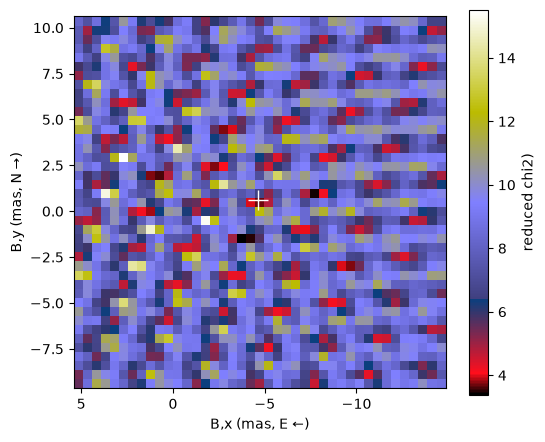

In [23]:

plt.figure(figsize=(6, 5))

plt.pcolormesh(xs, ys, chi2, cmap='gist_stern')

plt.plot(x3, y3, marker='+', color='w', ms=14, mew = 1)


plt.colorbar(label='reduced chi2)')
plt.gca().invert_xaxis(); plt.gca().set_aspect('equal')
plt.xlabel('B,x (mas, E ←)'); plt.ylabel('B,y (mas, N →)')



In [24]:
# Print the n grid points with the lowest chi2, with their B,x and B,y

n = 10                                           # how many to print

order = np.argsort(chi2, axis=None)              # flat indices, lowest chi2 first
order = order[np.isfinite(chi2.flat[order])]     # drop NaN (uncomputed) points

print(f'Top {min(n, len(order))} lowest chi2 grid points')
print('  rank    chi2r       B,x        B,y     sep(mas)   PA(deg)')
for rank, k in enumerate(order[:n], start=1):
    j, i = np.unravel_index(k, chi2.shape)       # row (y), column (x)
    x, y = xs[i], ys[j]
    print(f'{rank}  {chi2[j, i]}  {x}  {y}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}')

print('  rank    chi2r      sep(mas)   PA(deg)')
for rank, k in enumerate(order[:n], start=1):
    j, i = np.unravel_index(k, chi2.shape)       # row (y), column (x)
    x, y = xs[i], ys[j]
    print(f'{rank}  {chi2[j, i]} {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}')

Top 10 lowest chi2 grid points
  rank    chi2r       B,x        B,y     sep(mas)   PA(deg)
1  3.377223383102109  -3.7322963321945615  -1.502074060376632  4.023215429748862  248.07752957299056
2  3.437511978724312  -7.687331624502317  0.9698229973157151  7.748265880259651  277.1903686298815
3  3.509978110941763  -4.226675743733031  -1.502074060376632  4.485645363324826  250.43582802145067
4  3.6035719411405287  0.7171183716516634  1.958581820392654  2.085737640771949  20.109782456947105
5  3.696250178444401  -4.7210551552715  0.47544358577724566  4.744935024041145  275.75070078446254
6  3.723780999954323  -9.664849270656195  -2.9852122949920403  10.115374628291095  252.83548649886427
7  3.7417230930511063  -2.7435375091176226  4.430478878085001  5.211155452785175  328.2324791723853
8  3.7482562928665155  1.2114977831901328  1.958581820392654  2.3029914515358514  31.73922275593432
9  3.7513015267242915  -2.249158097579153  2.4529612319311234  3.3280220782415086  317.48180760347554
10  3.

/Users/ethanchen/ASTRO2/ASTRO399/.venv/lib/python3.14/site-packages/pmoired/__init__.py:3255: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


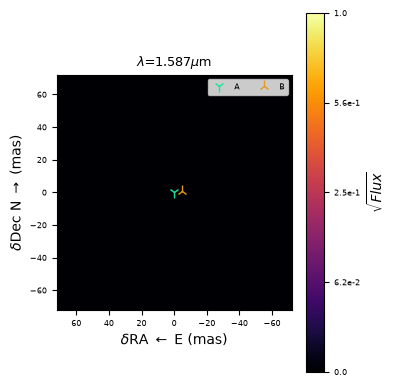

In [25]:
# To scale, based off calculated uds
disp = dict(oi.bestfit['best'])
oi.showModel(disp, imFov=1.2*maxsep1, imPix=0.1, imPow=0.5, showSED=False)

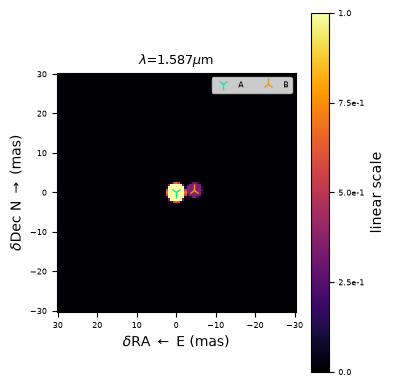

In [26]:
# Not to scale
disp = dict(oi.bestfit['best'])
disp['A,ud'] = 5      # display size only, not measured
disp['B,ud'] = 4
oi.showModel(disp, imFov=0.5*maxsep1, imPix=0.6, imPow=1, showSED=False)